# 01 · Limpieza de las fuentes (RNDC y SICE-TAC, diciembre de 2025)

Este es el primer paso del flujo. Aquí no se cruza nada todavía: cada fuente se limpia por separado y se guarda en un archivo limpio. El notebook 02 toma esos archivos, los cruza y arma la etiqueta; el notebook 03 entrena los modelos.

La idea de separar la limpieza es que cada decisión quede escrita una sola vez y que cualquiera pueda ver cuántos viajes se perdieron en cada paso y por qué. Al final queda una bitácora en `bitacora_limpieza.csv` con ese conteo.

Archivos que hay que subir a Colab: `RNDC_202512_crudo.csv.gz` y `SICETAC_202512_crudo.csv.gz`.

Archivos que salen: `rndc_limpio_dic2025.csv.gz`, `sicetac_costos_c2_dic2025.csv`, `bitacora_limpieza.csv` y `fig_limpieza_kg.png`.

## 1. Carga

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = '/content' if os.path.exists('/content') else '.'
rndc = pd.read_csv(f'{BASE}/RNDC_202512_crudo.csv.gz', low_memory=False)
sic = pd.read_csv(f'{BASE}/SICETAC_202512_crudo.csv.gz', low_memory=False)
print('RNDC crudo:', rndc.shape, '| SICE-TAC crudo:', sic.shape)

bitacora = []
def anotar(fuente, paso, antes, despues, por_que):
    bitacora.append({'fuente': fuente, 'paso': paso, 'filas_antes': antes,
                     'filas_despues': despues, 'quitadas': antes - despues, 'por_que': por_que})
    print(f'{fuente:8s} | {paso:45s} {antes:>8,} -> {despues:>8,}  (-{antes - despues:,})')

RNDC crudo: (197548, 29) | SICE-TAC crudo: (1911276, 19)


## 2. RNDC: quedarnos con viajes comparables

El RNDC que publica el Ministerio no viene viaje por viaje: cada fila agrupa los viajes que comparten mes, configuración, ruta, mercancía y tipo de operación, y la columna `VIAJESTOTALES` dice cuántos son. En esas filas el pago y los kilos son la suma de todos. Si comparamos esa suma contra el costo de un solo viaje, cualquier fila de varios viajes parece rentable aunque no lo sea. Por eso nos quedamos con las filas de un solo viaje.

También filtramos camión rígido de dos ejes (el vehículo del proyecto) y operación general, porque los viajes multiparada, de ida y regreso o vacíos tienen otra lógica de costo que el SICE-TAC no modela igual.

In [2]:
n = len(rndc)
r = rndc[rndc['COD_CONFIG_VEHICULO'].astype(str).str.strip() == '2'].copy()
anotar('RNDC', 'Camión rígido de 2 ejes', n, len(r), 'Es el vehículo del proyecto; el SICE-TAC no costea camionetas')

n = len(r); r = r[r['OPERACIONTRANSPORTE'] == 'General']
anotar('RNDC', 'Operación general', n, len(r), 'Multiparada, ida y regreso o vacío tienen otra estructura de costo')

n = len(r); r = r[r['VIAJESTOTALES'] == 1]
anotar('RNDC', 'Un solo viaje por fila', n, len(r), 'En filas de varios viajes el pago es la suma; no se puede comparar con el costo de un viaje')

RNDC     | Camión rígido de 2 ejes                        197,548 ->   87,741  (-109,807)
RNDC     | Operación general                               87,741 ->   80,938  (-6,803)
RNDC     | Un solo viaje por fila                          80,938 ->   44,197  (-36,741)


## 3. RNDC: valores imposibles o que no tienen sentido para este camión

Aquí van tres reglas, todas con un argumento externo y no con un percentil elegido arbitrariamente.

Primero, pago, kilómetros y kilos tienen que ser mayores que cero. Un viaje pagado en cero o de cero kilómetros no se puede etiquetar.

Segundo, el peso. La Resolución 4100 de 2004, modificada por la Resolución 1782 de 2009, fija en 17 toneladas el peso bruto máximo de un camión rígido de dos ejes, lo que deja una capacidad de carga neta de unas 12 toneladas. Un viaje reportado con más de 12.000 kg no es de este camión o está mal digitado, y los que pasan de 17.000 kg son imposibles. En el otro extremo se conservan los viajes livianos: un camión puede despachar con poca carga (paquetes, repuestos, encargos pequeños) y el manifiesto es válido aunque el camión vaya casi vacío. El piso es 1 kg, que solo excluye pesos en cero.

Tercero, tres viajes tienen la naturaleza de carga registrada como un punto. Sin ese dato no se puede asignar el costo correcto, así que salen.

In [3]:
n = len(r); r = r[(r['VALORESPAGADOS'] > 0) & (r['KILOMETROS'] > 0) & (r['KILOGRAMOS'] > 0)]
anotar('RNDC', 'Pago, km y kg mayores que cero', n, len(r), 'Sin estos valores no hay etiqueta ni predictores')

KG_MIN, KG_MAX = 1, 12_000
kg_antes = r['KILOGRAMOS'].copy()
n = len(r); r = r[r['KILOGRAMOS'].between(KG_MIN, KG_MAX)]
anotar('RNDC', f'Peso entre {KG_MIN:,} y {KG_MAX:,} kg', n, len(r), 'Capacidad neta de un C2 según Res. 4100/2004 (mod. Res. 1782/2009); los viajes livianos se conservan')

n = len(r); r = r[r['NATURALEZACARGA'].str.strip() != '.']
anotar('RNDC', 'Naturaleza de la carga registrada', n, len(r), 'Sin naturaleza no se sabe qué costo aplicar')

RNDC     | Pago, km y kg mayores que cero                  44,197 ->   37,728  (-6,469)
RNDC     | Peso entre 1 y 12,000 kg                        37,728 ->   37,646  (-82)
RNDC     | Naturaleza de la carga registrada               37,646 ->   37,643  (-3)


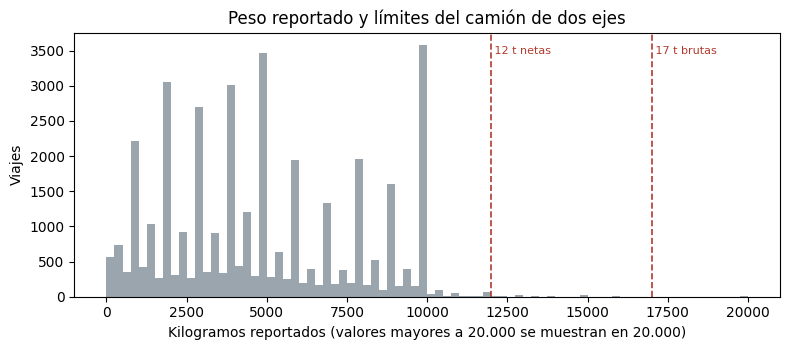

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(kg_antes.clip(upper=20_000), bins=80, color='#9AA5AD')
for x, t in [(KG_MAX, '12 t netas'), (17_000, '17 t brutas')]:
    ax.axvline(x, color='#B23A2E', lw=1.2, ls='--'); ax.text(x, ax.get_ylim()[1] * 0.92, ' ' + t, color='#B23A2E', fontsize=8)
ax.set_xlabel('Kilogramos reportados (valores mayores a 20.000 se muestran en 20.000)')
ax.set_ylabel('Viajes'); ax.set_title('Peso reportado y límites del camión de dos ejes')
plt.tight_layout(); plt.savefig('fig_limpieza_kg.png', dpi=200); plt.show()

## 4. RNDC: duplicados y vacíos

Revisamos si hay filas exactamente repetidas en el archivo. No hay ninguna, así que no se quita nada. Cuando más adelante aparecen filas iguales es porque solo miramos algunas columnas: son viajes distintos que coinciden en ruta, peso y mercancía, y borrarlos sería perder datos reales.

El único vacío está en la descripción de la mercancía. El código de la mercancía, en cambio, siempre está. Con ese código armamos el capítulo arancelario (los dígitos 3 y 4 del código de seis), que agrupa más de mil descripciones distintas en 99 grupos con sentido, como “plásticos”, “máquinas” o “misceláneos”. Así no hay que imputar nada.

In [5]:
print('Filas exactamente repetidas en el RNDC filtrado:', int(r.duplicated().sum()))
print('Descripciones de mercancía vacías:', int(r['MERCANCIA'].isna().sum()))
print('Códigos de mercancía vacíos:', int(r['CODMERCANCIA'].isna().sum()))

r['CODMERCANCIA'] = r['CODMERCANCIA'].astype(str).str.strip().str.zfill(6)
r['CAPITULO'] = 'CAP_' + r['CODMERCANCIA'].str[2:4]
r['MERCANCIA'] = r['MERCANCIA'].fillna('SIN DESCRIPCION')
print('Descripciones distintas:', r['MERCANCIA'].nunique(), '| Capítulos distintos:', r['CAPITULO'].nunique())

for c in ['CODMUNICIPIOORIGEN', 'CODMUNICIPIODESTINO']:
    r[c] = r[c].astype(float).astype('int64')

cols_rndc = ['MES', 'CODMUNICIPIOORIGEN', 'MUNICIPIOORIGEN', 'DEPARTAMENTOORIGEN',
             'CODMUNICIPIODESTINO', 'MUNICIPIODESTINO', 'DEPARTAMENTODESTINO',
             'CODMERCANCIA', 'CAPITULO', 'MERCANCIA', 'NATURALEZACARGA',
             'KILOGRAMOS', 'KILOMETROS', 'VALORESPAGADOS']
rndc_limpio = r[cols_rndc].reset_index(drop=True)
rndc_limpio.to_csv('rndc_limpio_dic2025.csv.gz', index=False)
print('RNDC limpio guardado:', rndc_limpio.shape)

Filas exactamente repetidas en el RNDC filtrado: 0
Descripciones de mercancía vacías: 603
Códigos de mercancía vacíos: 0
Descripciones distintas: 1011 | Capítulos distintos: 99


RNDC limpio guardado: (37643, 14)


## 5. SICE-TAC: un costo por ruta que sí corresponda al viaje

Aquí estaba el ajuste más importante del proyecto. En la primera entrega el costo se calculó como valor de movilización más valor hora por **horas de recorrido**, y luego se tomó la mediana de todas las filas de la ruta. Revisando cómo funciona el SICE-TAC aparecen tres problemas.

El primero es la fórmula. El valor hora del SICE-TAC es lo que se paga por cada **hora logística** (cargue, descargue y esperas), no por cada hora manejando; el tiempo de manejo ya está dentro del valor de movilización. Según la Circular Externa 20251010000577 de 2025 del Ministerio de Transporte, desde febrero de 2025 se reconocen como mínimo 4 horas logísticas en rutas de hasta 8 horas de tránsito y 8 horas en rutas más largas. Multiplicar por las horas de recorrido cobraba dos veces el tiempo de viaje, y más entre más larga la ruta.

El segundo es la vía. Algunas rutas tienen una vía estándar y otras alternas más largas. Todas las rutas tienen exactamente una vía estándar, así que usamos esa.

El tercero es la carrocería. La mediana mezclaba carga general con furgón refrigerado, tanque o portacontenedores, que son mucho más caros. El RNDC sí dice si la carga es refrigerada. Entonces asignamos el costo de carga refrigerada a los viajes refrigerados y el costo de carga general a todos los demás. Dentro de carga general las carrocerías cuestan casi lo mismo (en la ruta típica la más cara cuesta 5,5 % más que la más barata), así que la incertidumbre baja mucho.

La fórmula debe verificarse a mano con una ruta en la herramienta web del SICE-TAC. Al final de esta sección está el ejemplo Bogotá–Medellín: con el mínimo de 8 horas logísticas, el costo en estacas debe dar 1.900.050 pesos.

In [6]:
n = len(sic)
s = sic[sic['CONFIGURACION'].astype(str).str.strip() == '2'].copy()
anotar('SICE-TAC', 'Configuración 2 (rígido 2 ejes)', n, len(s), 'Mismo vehículo que el RNDC filtrado')
n = len(s); s = s[s['CONDICIONCARGA'] == 'CARGADO']
anotar('SICE-TAC', 'Condición cargado', n, len(s), 'El RNDC registra viajes con carga')

# Costo con la fórmula de la primera entrega (solo para comparar después)
s['COSTO_FORMULA_ANTERIOR'] = s['VALORMOVILIZA'] + s['VALORHORA'] * s['HORASRECORRIDO']
for c in ['ORIGEN', 'DESTINO']:
    s[c] = s[c].astype(float).astype('int64')
anterior = (s.groupby(['ORIGEN', 'DESTINO'])['COSTO_FORMULA_ANTERIOR'].median()
              .rename('COSTO_FORMULA_ANTERIOR'))

n = len(s); s = s[s['VIAESTANDAR'] == 'SI']
anotar('SICE-TAC', 'Vía estándar', n, len(s), 'Una sola vía por ruta; las alternas son más largas')
print('Vías estándar por ruta:', s.groupby(['ORIGEN', 'DESTINO'])['RUTASID'].nunique().value_counts().to_dict())

n = len(s); s = s[s['NOMBRETIPOCARGA'].isin(['General', 'Carga Refrigerada'])]
anotar('SICE-TAC', 'Tipo de carga general o refrigerada', n, len(s), 'Se asigna según la naturaleza de la carga del RNDC')

s['HORAS_LOGISTICAS'] = np.where(s['HORASRECORRIDO'] <= 8, 4, 8)
s['COSTO'] = s['VALORMOVILIZA'] + s['VALORHORA'] * s['HORAS_LOGISTICAS']

SICE-TAC | Configuración 2 (rígido 2 ejes)               1,911,276 ->  224,856  (-1,686,420)
SICE-TAC | Condición cargado                              224,856 ->  112,428  (-112,428)
SICE-TAC | Vía estándar                                   112,428 ->   97,728  (-14,700)
Vías estándar por ruta: {1: 8144}
SICE-TAC | Tipo de carga general o refrigerada             97,728 ->   40,720  (-57,008)


In [7]:
gen = (s[s['NOMBRETIPOCARGA'] == 'General'].groupby(['ORIGEN', 'DESTINO'])
         .agg(KM_SICETAC=('KILOMETROS', 'first'), HORAS_TRANSITO=('HORASRECORRIDO', 'first'),
              HORAS_LOGISTICAS=('HORAS_LOGISTICAS', 'first'),
              COSTO_GENERAL=('COSTO', 'median'), COSTO_GENERAL_MIN=('COSTO', 'min'),
              COSTO_GENERAL_MAX=('COSTO', 'max')))
ref = (s[s['NOMBRETIPOCARGA'] == 'Carga Refrigerada'].groupby(['ORIGEN', 'DESTINO'])
         .agg(COSTO_REFRIGERADA=('COSTO', 'median')))
costos = gen.join(ref).join(anterior).reset_index()
print('Rutas con costo:', len(costos), '| sin costo refrigerado:', int(costos['COSTO_REFRIGERADA'].isna().sum()))
print('Rutas de más de 8 horas de tránsito:', f"{(costos['HORAS_TRANSITO'] > 8).mean():.1%}")
print('Diferencia máxima entre carrocerías de carga general (mediana por ruta):',
      f"{(costos['COSTO_GENERAL_MAX'] / costos['COSTO_GENERAL_MIN'] - 1).median():.1%}")
costos.to_csv('sicetac_costos_c2_dic2025.csv', index=False)

Rutas con costo: 8144 | sin costo refrigerado: 0
Rutas de más de 8 horas de tránsito: 52.2%
Diferencia máxima entre carrocerías de carga general (mediana por ruta): 5.5%


In [8]:
# Ejemplo para verificar a mano en la herramienta SICE-TAC: Bogotá (11001000) -> Medellín (5001000)
ej = s[(s['ORIGEN'] == 11001000) & (s['DESTINO'] == 5001000) & (s['NOMBRETIPOCARGA'] == 'General')]
display(ej[['NOMBREUNIDADTRANSPORTE', 'KILOMETROS', 'HORASRECORRIDO', 'VALORMOVILIZA', 'VALORHORA',
            'HORAS_LOGISTICAS', 'COSTO', 'COSTO_FORMULA_ANTERIOR']])

,NOMBREUNIDADTRANSPORTE,KILOMETROS,HORASRECORRIDO,VALORMOVILIZA,VALORHORA,HORAS_LOGISTICAS,COSTO,COSTO_FORMULA_ANTERIOR
28616,ESTACAS,429.0,11.71,1603290.0,37095.0,8,1900050.0,2037672.45
28629,ESTIBAS,429.0,11.71,1603290.0,37095.0,8,1900050.0,2037672.45
28638,FURGON,429.0,11.71,1668201.0,42639.0,8,2009313.0,2167503.69
28640,PLATAFORMA,429.0,11.71,1603290.0,37095.0,8,1900050.0,2037672.45


## 6. Bitácora

Esta tabla resume cada paso. Es la que va en el informe para mostrar de dónde salen los números.

In [9]:
bit = pd.DataFrame(bitacora)
bit.to_csv('bitacora_limpieza.csv', index=False)
bit

,fuente,paso,filas_antes,filas_despues,quitadas,por_que
0,RNDC,Camión rígido de 2 ejes,197548,87741,109807,Es el vehículo del proyecto; el SICE-TAC no co...
1,RNDC,Operación general,87741,80938,6803,"Multiparada, ida y regreso o vacío tienen otra..."
2,RNDC,Un solo viaje por fila,80938,44197,36741,En filas de varios viajes el pago es la suma; ...
3,RNDC,"Pago, km y kg mayores que cero",44197,37728,6469,Sin estos valores no hay etiqueta ni predictores
4,RNDC,"Peso entre 1 y 12,000 kg",37728,37646,82,Capacidad neta de un C2 según Res. 4100/2004 (...
5,RNDC,Naturaleza de la carga registrada,37646,37643,3,Sin naturaleza no se sabe qué costo aplicar
6,SICE-TAC,Configuración 2 (rígido 2 ejes),1911276,224856,1686420,Mismo vehículo que el RNDC filtrado
7,SICE-TAC,Condición cargado,224856,112428,112428,El RNDC registra viajes con carga
8,SICE-TAC,Vía estándar,112428,97728,14700,Una sola vía por ruta; las alternas son más la...
9,SICE-TAC,Tipo de carga general o refrigerada,97728,40720,57008,Se asigna según la naturaleza de la carga del ...
